<a href="https://colab.research.google.com/github/liamcohenn/tp_laboratorio_futbol/blob/main/notebooks/tp_inferiores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Trabajo Práctico Grupal - Laboratorio**

**Integrantes:** Liam Cohen, Renzo Bianco Maura, Federico Kurozwan y Milagros Leon

**Pregunta:** ¿Qué peso y qué rentabilidad tienen las ventas de jugadores formados en inferiores frente a las de jugadores comprados?

**Dataset:** Football Data from Transfermarkt (tablas transfers, players, clubs y competitions), subido al repositorio del grupo.

**Ligas analizadas:** Premier League (GB1), LaLiga (ES1), Ligue 1 (FR1), Primeira Liga (PO1), Eredivisie (NL1), Argentina (ARG1), México (MEX1) y Arabia Saudita (SA1).

# 3.1. Carga y exploración inicial

 ### Carga de datos



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "https://raw.githubusercontent.com/liamcohenn/tp_laboratorio_futbol/main/datos/raw/"

transfers = pd.read_csv(BASE + "transfers.csv.gz")
players = pd.read_csv(BASE + "players.csv.gz")
clubs = pd.read_csv(BASE + "clubs.csv.gz")
competitions = pd.read_csv(BASE + "competitions.csv.gz")

### Primeras filas de `transfers`

In [ ]:
transfers.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur,player_name
0,467994,2030-06-30,25/26,5621,749,Reggiana,FC Empoli,0.0,700000.0,Luca Belardinelli
1,645842,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,150000.0,Chan-gi An
2,677470,2028-02-02,27/28,6505,3535,Gimcheon Sangmu,Ulsan HD,0.0,400000.0,Yool Heo
3,709155,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,325000.0,Jae-hyeok Oh
4,728133,2028-02-02,27/28,6505,35759,Gimcheon Sangmu,Bucheon FC,0.0,175000.0,Sang-hyeok Lee


### Últimas filas de `transfers`

In [ ]:
transfers.tail()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur,player_name
175160,22141,1994-07-01,94/95,59178,29463,Castellammare,Sorrento Youth,NaN,NaN,Antonio Mirante
175161,33829,1994-07-01,94/95,58405,53957,FC Penafiel You,Sporting Yth.,NaN,NaN,José Fonte
175162,40680,1994-07-01,94/95,47320,47318,Lichtenw. Yth.,Schornbach Yth.,0.0,NaN,Sven Ulreich
175163,21101,1993-07-01,93/94,140068,129841,Host.-Her. Yth.,Drnovice Yth.,NaN,NaN,Milan Petrzela
175164,61989,1993-07-01,93/94,55345,55343,A. Ickern Yth.,VfR Rauxel Yth.,0.0,NaN,Michael Esser


### Cantidad de filas y columnas de `transfers`:

In [ ]:
transfers.shape

(175165, 10)

### Tipo de dato de cada columna de `transfers`:

In [ ]:
transfers.dtypes

,0
player_id,int64
transfer_date,object
transfer_season,object
from_club_id,int64
to_club_id,int64
from_club_name,object
to_club_name,object
transfer_fee,float64
market_value_in_eur,float64
player_name,object


### Valores nulos en `transfers`:

In [ ]:
transfers.isnull().sum()

,0
player_id,0
transfer_date,0
transfer_season,0
from_club_id,0
to_club_id,0
from_club_name,0
to_club_name,0
transfer_fee,61526
market_value_in_eur,68160
player_name,0


### Filas duplicadas en `transfers`:

In [ ]:
transfers.duplicated().sum()

np.int64(0)

### Estadísticas descriptivas de `transfers`:

In [ ]:
transfers.describe()

,player_id,from_club_id,to_club_id,transfer_fee,market_value_in_eur
count,1.751650e+05,175165.000000,175165.000000,1.136390e+05,1.070050e+05
mean,5.052302e+05,21072.165227,16527.056609,7.398360e+05,1.753554e+06
std,3.129336e+05,27801.575593,24383.722776,4.245003e+06,4.714253e+06
min,2.989000e+03,1.000000,1.000000,0.000000e+00,1.000000e+04
25%,2.568660e+05,1084.000000,865.000000,0.000000e+00,2.000000e+05
50%,4.521640e+05,9259.000000,6107.000000,0.000000e+00,4.250000e+05
75%,7.000310e+05,31098.000000,21082.000000,0.000000e+00,1.200000e+06
max,1.545443e+06,142714.000000,142487.000000,2.220000e+08,1.800000e+08


#### Pasamos ahora con la tabla `players`
### Primeras filas de `players`:

In [ ]:
players.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


### Últimas filas de `players`:

In [ ]:
players.tail()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
50144,1546617,Yahya Mousa,Gharawi,Yahya Mousa Gharawi,2025,34911,yahya-mousa-gharawi,NaN,NaN,Saudi Arabia,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/yahya-mousa-gh...,SA1,Neom Sports Club,NaN,NaN
50145,1547421,Szabolcs,Nyitra,Szabolcs Nyitra,2025,37255,szabolcs-nyitra,NaN,NaN,Romania,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/szabolcs-nyitr...,RO1,FK Csikszereda Miercurea Ciuc,NaN,NaN
50146,1548905,Iustin,Filote,Iustin Filote,2025,8818,iustin-filote,NaN,NaN,Romania,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/iustin-filote/...,RO1,FC Botosani,NaN,NaN
50147,1550699,Vukasin,Zdravkovic,Vukasin Zdravkovic,2025,7567,vukasin-zdravkovic,NaN,NaN,Serbia,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/vukasin-zdravk...,SER1,FK Radnicki Nis,NaN,NaN
50148,1555760,Aidan,Melville,Aidan Melville,2025,32371,aidan-melville,United States,"Portland, Maine",Puerto Rico,...,NaN,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,17759.0,https://www.transfermarkt.co.uk/aidan-melville...,NaN,NaN,NaN,NaN


### Cantidad de filas y columnas de `players`:

In [ ]:
players.shape

(50149, 26)

### Tipo de dato de cada columna de `players`:

In [ ]:
players.dtypes

,0
player_id,int64
first_name,object
last_name,object
name,object
last_season,int64
current_club_id,int64
player_code,object
country_of_birth,object
city_of_birth,object
country_of_citizenship,object


### Valores nulos en `players`:

In [ ]:
players.isnull().sum()

,0
player_id,0
first_name,3164
last_name,0
name,0
last_season,0
current_club_id,0
player_code,0
country_of_birth,5885
city_of_birth,5608
country_of_citizenship,269


### Filas duplicadas en `players`:

In [ ]:
players.duplicated().sum()

np.int64(0)

### Estadísticas descriptivas de `players`:

In [ ]:
players.describe()

,player_id,last_season,current_club_id,height_in_cm,international_caps,international_goals,current_national_team_id,market_value_in_eur,highest_market_value_in_eur
count,5.014900e+04,50149.000000,50149.000000,45784.000000,19356.000000,19356.000000,3260.000000,4.152800e+04,4.152800e+04
mean,5.127845e+05,2021.668986,8547.636384,181.997445,11.370738,1.182941,9230.514417,1.511049e+06,3.450773e+06
std,3.864011e+05,4.248524,17501.460798,7.426226,18.988176,4.159747,6614.208583,5.854556e+06,9.347394e+06
min,1.000000e+01,2012.000000,2.000000,17.000000,0.000000,0.000000,3262.000000,1.000000e+04,1.000000e+04
25%,1.868480e+05,2018.000000,501.000000,177.000000,1.000000,0.000000,3590.000000,1.000000e+05,3.000000e+05
50%,4.269440e+05,2024.000000,1496.000000,182.000000,4.000000,0.000000,6133.000000,2.750000e+05,7.500000e+05
75%,8.014200e+05,2025.000000,6890.000000,187.000000,12.000000,1.000000,14165.000000,7.000000e+05,2.500000e+06
max,1.555760e+06,2025.000000,142301.000000,210.000000,233.000000,146.000000,53982.000000,2.000000e+08,2.000000e+08


## Comentarios sobre la primera parte del análisis


>

- **Tamaño:** `transfers` tiene 175.165 filas y 10 columnas; `players` tiene 50.149 filas y 26 columnas.


- **Duplicados:** no hay filas duplicadas ni en `transfers` ni en `players` (0 en las dos).

- **Fechas:** las transferencias van del 1 de julio de 1993 al 30 de junio de 2030. Las primeras filas de `.head()` muestran fechas futuras: son 520 movimientos programados después del 6 de julio de 2026, como finales de préstamo o regresos de jugadores que hacen el servicio militar en Corea con el Gimcheon Sangmu. Como todavía no ocurrieron, se eliminan más adelante (Transformación 2).

 - **Valores nulos:** lo que más se nota es que a `transfers` le faltan muchos datos de dinero: `transfer_fee` tiene 61.526 nulos y `market_value_in_eur` tiene 68.160. Como no sabemos si esas transferencias fueron gratis o simplemente no se cargó el monto, para ingresos por ventas solo vamos a usar las filas que tienen `transfer_fee`. En `players` los nulos están sobre todo en datos de selección: `current_national_team_id` (46.889), `international_caps` e `international_goals` (30.793 cada una). También falta `agent_name` en 23.296 jugadores. Además, según la documentación del dataset, un monto igual a 0 corresponde a pases libres y préstamos, por eso la mediana de `transfer_fee` es 0.

- **Valores llamativos:** en `transfer_fee` el máximo es de €222 millones, pero la mediana es €0, o sea que la mayoría de los movimientos tiene un monto de cero, solo unos pocos son muy caros y no hay valores negativos. El valor de mercado más alto es €180 millones. En `players`, un jugador figura con 17 cm de altura, que no puede ser real y seguramente es un error de carga; la altura máxima es 210 cm.







## 3.2 Pregunta de investigación

**a) ¿Cuál es la pregunta?**
¿Qué peso y qué rentabilidad tienen las ventas de jugadores formados en inferiores frente a las de jugadores comprados, en los clubes de 8 ligas?

**b) ¿Por qué vale la pena responderla?**
Se entiende que formar jugadores en inferiores le sale mucho más barato a un club que comprarlos, ya que después los puede vender y ganar plata con eso. Saber cuánto pesan esas ventas sobre el total, y si dejan más ganancia que la venta de jugadores comprados, ayuda a entender si a un club le conviene invertir en sus inferiores o comprar jugadores ya formados.

**c) ¿Qué respuesta encontraron?** completar al terminar el trabajo              
Las ventas de jugadores formados en inferiores representan el 26% de las ventas y el 23% de los ingresos por pases de los clubes de las 8 ligas, así que la mayor parte del dinero viene de revender jugadores comprados. Pero son más rentables: la ganancia mediana de un canterano es de €3 M, casi el triple que la de un comprado (€1,1 M), aunque esa diferencia no descuenta el costo de mantener las inferiores. El peso de las inferiores cambia mucho según la liga: es máximo en Argentina (entre 33% y 49% de los ingresos) y en las formadoras europeas (cerca del 30%), y mínimo en LaLiga, la Premier y Arabia Saudita. Además, los clubes venden a sus canteranos alrededor de los 21 años, y entre los comprados, los que llegan más jóvenes dejan más ganancia en la reventa.

# 3.3. Transformaciones y resumen estadístico

#### **Transformación 1: pasar las fechas a formato fecha.** Las columnas `transfer_date` y `date_of_birth` están como texto. Las convertimos con `pd.to_datetime()` para poder restarlas y compararlas.

In [ ]:
transfers["transfer_date"] = pd.to_datetime(transfers["transfer_date"])
players["date_of_birth"] = pd.to_datetime(players["date_of_birth"])

transfers.dtypes

,0
player_id,int64
transfer_date,datetime64[ns]
transfer_season,object
from_club_id,int64
to_club_id,int64
from_club_name,object
to_club_name,object
transfer_fee,float64
market_value_in_eur,float64
player_name,object


#### **Transformación 2: sacar las transferencias posteriores al 6 de julio de 2026.** Son finales de préstamo programados, todavía no pasaron, así que no sirven para el análisis. Primero contamos cuántas hay (deberían ser 520) y después las eliminamos.

In [ ]:
fecha_corte = pd.to_datetime("2026-07-06")

print("Transferencias posteriores al corte:", (transfers["transfer_date"] > fecha_corte).sum())

transfers = transfers[transfers["transfer_date"] <= fecha_corte]

print("Fecha máxima ahora:", transfers["transfer_date"].max())
print("Filas que quedan:", transfers.shape[0])

Transferencias posteriores al corte: 520
Fecha máxima ahora: 2026-07-02 00:00:00
Filas que quedan: 174645


#### **Transformación 3: calcular la edad del jugador en cada transferencia.** Pegamos la fecha de nacimiento de cada jugador a la tabla `transfers` (con `merge`, usando `player_id`) y calculamos la edad como la diferencia entre la fecha de la transferencia y la de nacimiento, en años. La vamos a necesitar en la Parte 2 para saber si un jugador entró al club antes de los 18.

In [ ]:
transfers = transfers.merge(players[["player_id", "date_of_birth"]], on="player_id", how="left")

transfers["edad"] = (transfers["transfer_date"] - transfers["date_of_birth"]).dt.days / 365.25

transfers[["player_name", "transfer_date", "date_of_birth", "edad"]].head()

,player_name,transfer_date,date_of_birth,edad
0,César Augusto,2026-07-02,2003-08-23,22.858316
1,Kingstone Mutandwa,2026-07-02,2003-01-05,23.488022
2,James Milner,2026-07-01,1986-01-04,40.487337
3,Lukas Podolski,2026-07-01,1985-06-04,41.073238
4,Raúl Albiol,2026-07-01,1985-09-04,40.821355


#### **Transformación 4: lista de clubes de las 8 ligas.** Armamos la lista de ligas y nos quedamos con los clubes de la tabla `clubs` que juegan en alguna de ellas.

**Cobertura geográfica:** quedaron 241 clubes de las 8 ligas: Premier League (37), Ligue 1 (36), Portugal (35), LaLiga (33), Argentina (32), Países Bajos (29), Arabia Saudita (21) y México (18). Son más clubes que los equipos de cada temporada porque la tabla incluye clubes que jugaron en esas ligas en distintos años.

In [ ]:
ligas = ["GB1", "ES1", "FR1", "PO1", "NL1", "ARG1", "MEX1", "SA1"]

clubes_ligas = clubs[clubs["domestic_competition_id"].isin(ligas)]

clubes_ligas["domestic_competition_id"].value_counts()

,count
domestic_competition_id,
GB1,37
FR1,36
PO1,35
ES1,33
ARG1,32
NL1,29
SA1,21
MEX1,18


#### **Transformación 5: nombres de los clubes de las 8 ligas.** La tabla clubs tiene los nombres oficiales largos (por ejemplo, “Futbol Club Barcelona”), pero en transfers aparecen los nombres cortos (“Barcelona”). Armamos un diccionario con el nombre corto de cada club, que vamos a usar para reconocer a sus equipos juveniles.

Asistencia de IA: las celdas de la Parte 2 se desarrollaron con asistencia de Claude. Prompt utilizado: “Escribí en pandas una regla para clasificar las ventas de jugadores como canteranos o comprados, unificando los equipos juveniles con su club y sin contar los regresos de préstamo como compras”.

In [ ]:
import re

ids_ligas = set(clubes_ligas["club_id"])

salidas = transfers[transfers["from_club_id"].isin(ids_ligas)][["from_club_id", "from_club_name"]]
salidas.columns = ["club_id", "nombre"]
llegadas = transfers[transfers["to_club_id"].isin(ids_ligas)][["to_club_id", "to_club_name"]]
llegadas.columns = ["club_id", "nombre"]

nombre_club = pd.concat([salidas, llegadas]).groupby("club_id")["nombre"].agg(lambda s: s.value_counts().index[0])
print("Clubes de las 8 ligas:", len(nombre_club))

Clubes de las 8 ligas: 241


#### **Transformación 6: reconocer los equipos juveniles.** Transfermarkt registra a los equipos juveniles y filiales como clubes distintos (“Ajax U21”, “Jong Ajax”, “Sporting CP U23”). Esta función le saca al nombre las marcas de juvenil (U21, B, II, Youth, etc.) y las siglas como FC o CF, y avisa si el nombre tenía alguna marca de juvenil. Así, “Sporting CP U23” queda como “sporting”, igual que el club de primera.

In [ ]:
JUVENIL = r"\s+(U\d{2}|Y\d{2}|Sub-?\d{2}|Youth|Yout|You|Yth\.?|Y|Jgd\.?|Juv\.?|Juvenil|Res\.?|Reserves?|B|C|II|III|Atlètic|23)$"
SIGLAS = {"fc", "cf", "ud", "rcd", "as", "ca", "ea", "sc", "ac", "afc", "sl", "cp", "club"}

def normalizar(nombre):
    original = str(nombre).strip()
    n = re.sub(r"^Jong\s+", "", original)
    es_juvenil = n != original
    while re.search(JUVENIL, n):
        n = re.sub(JUVENIL, "", n).strip()
        es_juvenil = True
    palabras = [p for p in n.lower().split() if p not in SIGLAS]
    return " ".join(palabras), es_juvenil

print(normalizar("Ajax U21"))
print(normalizar("Jong Ajax"))
print(normalizar("Sporting CP U23"))
print(normalizar("River Plate"))

('ajax', True)
('ajax', True)
('sporting', True)
('river plate', False)


#### **Transformación 7: unificar los equipos juveniles con su club.** A cada club de cada transferencia le asignamos su “familia”: si es un juvenil de un club de las 8 ligas, la familia es ese club; si no, es el mismo club. Solo unificamos cuando el nombre tenía una marca de juvenil, para no confundir clubes distintos con el mismo nombre (por ejemplo, River Plate de Uruguay). Dos juveniles no siguen el patrón y se agregan a mano: “Barça Atlètic” y “CABJ U20”.

In [ ]:
id_por_nombre_normalizado = {normalizar(nombre)[0]: club_id for club_id, nombre in nombre_club.items()}
id_por_nombre = {nombre: club_id for club_id, nombre in nombre_club.items()}

EQUIVALENCIAS_MANUALES = {"Barça Atlètic": "Barcelona", "CABJ U20": "Boca Juniors"}

def club_familia(club_id, nombre):
    if club_id in ids_ligas:
        return club_id
    if nombre in EQUIVALENCIAS_MANUALES:
        return id_por_nombre[EQUIVALENCIAS_MANUALES[nombre]]
    nombre_norm, es_juvenil = normalizar(nombre)
    if es_juvenil and nombre_norm in id_por_nombre_normalizado:
        return id_por_nombre_normalizado[nombre_norm]
    return club_id

pares = pd.concat([
    transfers[["from_club_id", "from_club_name"]].set_axis(["club_id", "nombre"], axis=1),
    transfers[["to_club_id", "to_club_name"]].set_axis(["club_id", "nombre"], axis=1),
]).drop_duplicates()
pares["familia"] = [club_familia(i, n) for i, n in zip(pares["club_id"], pares["nombre"])]
mapa_familia = dict(zip(zip(pares["club_id"], pares["nombre"]), pares["familia"]))

transfers["familia_origen"] = [mapa_familia[(i, n)] for i, n in zip(transfers["from_club_id"], transfers["from_club_name"])]
transfers["familia_destino"] = [mapa_familia[(i, n)] for i, n in zip(transfers["to_club_id"], transfers["to_club_name"])]

print("Equipos juveniles unificados con su club:", (pares["familia"] != pares["club_id"]).sum())

Equipos juveniles unificados con su club: 748


#### **Transformación 8: separar los pases internos y quedarnos con las ventas.** Un pase del juvenil a la primera del mismo club (por ejemplo, de “Benfica B” a “Benfica”) no es una venta, así que lo separamos. Después nos quedamos con las ventas de clubes de las 8 ligas que tienen monto mayor a cero, porque los préstamos y pases libres no generan ingresos.

In [ ]:
internos = transfers[transfers["familia_origen"] == transfers["familia_destino"]]
movimientos = transfers[transfers["familia_origen"] != transfers["familia_destino"]].sort_values(["player_id", "transfer_date"])

ventas_base = movimientos[movimientos["familia_origen"].isin(ids_ligas) & (movimientos["transfer_fee"] > 0)]

print("Movimientos internos (juveniles a primera):", len(internos))
print("Ventas con monto de clubes de las 8 ligas:", len(ventas_base))

Movimientos internos (juveniles a primera): 8855
Ventas con monto de clubes de las 8 ligas: 5280


#### **Transformación 9: clasificar cada venta como cantera o comprado.** Para cada venta buscamos cómo llegó el jugador al club, recorriendo sus llegadas de la más reciente a la más vieja:
Si la llegada es una vuelta de préstamo (llegó sin monto desde un club al que antes había salido sin monto), la ignoramos y seguimos buscando.
Si llegó antes de los 18 años y sin que se pagara nada, es cantera.
Si llegó después de los 18 o se pagó por él, es comprado, y el costo es lo que se pagó.
Si no tiene ninguna llegada registrada, estuvo en el club desde las inferiores: es cantera.

Así se corrigen los errores de la primera versión: un canterano que sale a préstamo y vuelve ya no cuenta como comprado gratis, y un juvenil comprado (como Frenkie de Jong, por quien el Ajax pagó €7,74 M para su sub-21) ya no cuenta como canterano.

In [ ]:
movimientos_por_jugador = dict(tuple(movimientos.groupby("player_id")))

primera_fecha_en_club = pd.concat([
    transfers[["player_id", "familia_origen", "transfer_date"]].set_axis(["player_id", "club", "fecha"], axis=1),
    transfers[["player_id", "familia_destino", "transfer_date"]].set_axis(["player_id", "club", "fecha"], axis=1),
]).groupby(["player_id", "club"])["fecha"].min()

def sin_monto(monto):
    return pd.isna(monto) or monto == 0

def clasificar(venta):
    club = venta.familia_origen
    movs = movimientos_por_jugador[venta.player_id]
    anteriores = movs[movs["transfer_date"] < venta.transfer_date]
    salidas_club = anteriores[anteriores["familia_origen"] == club]
    llegadas_club = anteriores[anteriores["familia_destino"] == club].sort_values("transfer_date", ascending=False)

    for _, llegada in llegadas_club.iterrows():
        salio_prestado = salidas_club[
            (salidas_club["familia_destino"] == llegada["familia_origen"])
            & (salidas_club["transfer_date"] < llegada["transfer_date"])
            & salidas_club["transfer_fee"].apply(sin_monto)
        ]
        if sin_monto(llegada["transfer_fee"]) and len(salio_prestado) > 0:
            continue
        if llegada["edad"] < 18 and sin_monto(llegada["transfer_fee"]):
            return "cantera", 0.0, llegada["transfer_date"]
        return "comprado", llegada["transfer_fee"], llegada["transfer_date"]

    return "cantera", 0.0, primera_fecha_en_club[(venta.player_id, club)]

resultados = [clasificar(v) for v in ventas_base.itertuples()]
ventas_base = ventas_base.assign(
    grupo=[r[0] for r in resultados],
    costo=[r[1] for r in resultados],
    fecha_llegada=[r[2] for r in resultados],
)
ventas_base["grupo"].value_counts()

,count
grupo,
comprado,3911
cantera,1369


#### **Tabla final de ventas.** Armamos la tabla ventas con una fila por venta y las columnas que usan los resúmenes, los gráficos y el sitio web. Los montos se pasan a millones de euros para que sean más fáciles de leer.

In [ ]:
liga_por_club = dict(zip(clubs["club_id"], clubs["domestic_competition_id"]))

ventas = pd.DataFrame({
    "jugador": ventas_base["player_name"],
    "club_vendedor": ventas_base["familia_origen"].map(nombre_club),
    "club_comprador": ventas_base["to_club_name"],
    "liga": ventas_base["familia_origen"].map(liga_por_club),
    "temporada_venta": ventas_base["transfer_date"].dt.year,
    "grupo": ventas_base["grupo"],
    "fee_venta": ventas_base["transfer_fee"] / 1_000_000,
    "fee_compra": ventas_base["costo"] / 1_000_000,
    "anios_en_club": ((ventas_base["transfer_date"] - ventas_base["fecha_llegada"]).dt.days / 365.25).round(1),
    "edad_venta": ventas_base["edad"].round(1),
}).reset_index(drop=True)
ventas.head()

,jugador,club_vendedor,club_comprador,liga,temporada_venta,grupo,fee_venta,fee_compra,anios_en_club,edad_venta
0,James Milner,Leeds,Newcastle,GB1,2004,cantera,7.40,0.0,2.0,18.5
1,James Milner,Newcastle,Aston Villa,GB1,2008,comprado,15.00,7.4,4.2,22.7
2,James Milner,Aston Villa,Man City,GB1,2010,comprado,22.00,15.0,2.0,24.6
3,Boy Waterman,Heerenveen,AZ Alkmaar,NL1,2007,cantera,3.00,0.0,6.0,23.4
4,Pepe Reina,Barcelona,Villarreal,ES1,2002,cantera,0.75,0.0,3.0,19.8


#### **Control de la clasificación.** Verificamos la regla con casos conocidos: Gonçalo Ramos y Rúben Dias se formaron en Benfica; Frenkie de Jong fue comprado por el Ajax para su sub-21; Enzo Fernández se formó en River y Benfica lo compró. También contamos cuántos comprados tienen costo 0, que deberían ser solo los que llegaron con el pase libre.

In [ ]:
casos = [("Gonçalo Ramos", "Benfica", "cantera"),
         ("Rúben Dias", "Benfica", "cantera"),
         ("Frenkie de Jong", "Ajax", "comprado"),
         ("Enzo Fernández", "River Plate", "cantera"),
         ("Enzo Fernández", "Benfica", "comprado")]

for jugador, club, esperado in casos:
    fila = ventas[(ventas["jugador"] == jugador) & (ventas["club_vendedor"] == club)]
    obtenido = fila["grupo"].iloc[0] if len(fila) else "NO ENCONTRADO"
    print("OK   " if obtenido == esperado else "ERROR", jugador, "-", club, "→", obtenido)

comprados = ventas[ventas["grupo"] == "comprado"]
print("\nVentas totales:", len(ventas))
print("Comprados con costo 0 (pases libres):", (comprados["fee_compra"] == 0).sum(), "de", len(comprados))
print("Comprados con costo desconocido:", comprados["fee_compra"].isna().sum())
print(ventas.groupby("liga")["grupo"].value_counts().unstack())

OK    Gonçalo Ramos - Benfica → cantera
OK    Rúben Dias - Benfica → cantera
OK    Frenkie de Jong - Ajax → comprado
OK    Enzo Fernández - River Plate → cantera
OK    Enzo Fernández - Benfica → comprado

Ventas totales: 5280
Comprados con costo 0 (pases libres): 680 de 3911
Comprados con costo desconocido: 725
grupo  cantera  comprado
liga                    
ARG1       251       378
ES1        154       660
FR1        264       788
GB1        283       857
MEX1        39       176
NL1        205       451
PO1        131       542
SA1         42        59


# Parte 3: Resúmenes, gráficos y respuesta

**Asistencia de IA:** las celdas de la Parte 3 se desarrollaron con asistencia de Claude. **Prompt utilizado:** "¿Está todo bien o falta código?", enviado junto con el notebook con las Partes 1 y 2 terminadas, en una conversación en la que ya se había planificado la Parte 3 (resúmenes con `.groupby()`, tres gráficos de tipos distintos y exportación del CSV para el sitio). Las interpretaciones y los números se revisaron contra los resultados del notebook.

In [ ]:
import os
os.makedirs("figuras", exist_ok=True)

#### **Transformación 10: columnas para el análisis.** Agregamos cuatro columnas a ventas:
- ganancia: monto de venta menos costo de compra. Para los canteranos es igual al monto de venta, porque el dataset no registra el costo de formación. Queda vacía para los comprados con costo desconocido.
- edad_llegada: edad a la que el jugador llegó al club (edad de venta menos años en el club).
- tramo_edad_llegada: la edad de llegada agrupada en cuatro tramos, para comparar la ganancia de reventa.
- cantera_confirmada: marca los canteranos que aparecen en el club antes de los 18 años. Los demás canteranos son jugadores sin ninguna llegada registrada, que la regla supone formados en el club porque falta su historial juvenil.

In [ ]:
ventas["ganancia"] = ventas["fee_venta"] - ventas["fee_compra"]
ventas["edad_llegada"] = ventas["edad_venta"] - ventas["anios_en_club"]
ventas["tramo_edad_llegada"] = pd.cut(ventas["edad_llegada"], bins=[0, 21, 25, 29, 50], right=False,
                                      labels=["Hasta 20", "21 a 24", "25 a 28", "29 o más"])
ventas["cantera_confirmada"] = (ventas["grupo"] == "cantera") & (ventas["edad_llegada"] < 18)

ventas[["jugador", "grupo", "fee_venta", "fee_compra", "ganancia", "edad_llegada", "tramo_edad_llegada"]].head()

,jugador,grupo,fee_venta,fee_compra,ganancia,edad_llegada,tramo_edad_llegada
0,James Milner,cantera,7.40,0.0,7.40,16.5,Hasta 20
1,James Milner,comprado,15.00,7.4,7.60,18.5,Hasta 20
2,James Milner,comprado,22.00,15.0,7.00,22.6,21 a 24
3,Boy Waterman,cantera,3.00,0.0,3.00,17.4,Hasta 20
4,Pepe Reina,cantera,0.75,0.0,0.75,16.8,Hasta 20


#### **Resumen 1: peso y rentabilidad de cada grupo.** Agrupamos las ventas por origen del jugador y calculamos cuántas ventas hay, cuánto se recaudó, la venta mediana y la ganancia mediana. Usamos la mediana porque unos pocos pases muy caros distorsionan el promedio.

In [ ]:
resumen_grupo = ventas.groupby("grupo").agg(
    ventas=("fee_venta", "count"),
    ingresos_total=("fee_venta", "sum"),
    venta_mediana=("fee_venta", "median"),
    ganancia_mediana=("ganancia", "median"),
)
resumen_grupo["peso_ventas_%"] = resumen_grupo["ventas"] / resumen_grupo["ventas"].sum() * 100
resumen_grupo["peso_ingresos_%"] = resumen_grupo["ingresos_total"] / resumen_grupo["ingresos_total"].sum() * 100
resumen_grupo.round(2)

,ventas,ingresos_total,venta_mediana,ganancia_mediana,peso_ventas_%,peso_ingresos_%
grupo,,,,,,
cantera,1369,10117.49,3.00,3.00,25.93,22.89
comprado,3911,34088.06,3.55,1.11,74.07,77.11


Las ventas de canteranos son uno de cada cuatro pases (26%) y aportan el 23% de los ingresos. La mayor parte del dinero viene de revender jugadores comprados. Sin embargo, la venta típica de un canterano deja una ganancia mediana de €3M, casi el triple que la de un jugador comprado (€1,1 M), porque el club no pagó por él. Esta comparación favorece a las inferiores, ya que no incluye el costo de mantenerlas.

   #### **Resumen 2: peso de las inferiores en cada liga.** Calculamos qué porcentaje de los ingresos por ventas de cada liga viene de canteranos, con todos los canteranos y solo con los confirmados.

In [ ]:
ingresos_liga = ventas.pivot_table(index="liga", columns="grupo", values="fee_venta", aggfunc="sum")
ingresos_liga["ventas"] = ventas.groupby("liga").size()
ingresos_liga["cantera_%"] = ingresos_liga["cantera"] / (ingresos_liga["cantera"] + ingresos_liga["comprado"]) * 100
ingresos_liga["confirmada_%"] = (ventas[ventas["cantera_confirmada"]].groupby("liga")["fee_venta"].sum()
                                 / ventas.groupby("liga")["fee_venta"].sum() * 100)
ingresos_liga = ingresos_liga.sort_values("cantera_%", ascending=False)
ingresos_liga.round(1)

grupo,cantera,comprado,ventas,cantera_%,confirmada_%
liga,,,,,
ARG1,1068.5,1134.5,629,48.5,33.4
SA1,171.5,292.8,101,36.9,5.6
NL1,1037.7,2347.3,656,30.7,30.3
PO1,1442.5,3532.3,673,29.0,28.6
FR1,1937.6,7038.1,1052,21.6,20.9
MEX1,207.7,770.6,215,21.2,20.2
GB1,3046.3,12218.0,1140,20.0,18.0
ES1,1205.5,6754.4,814,15.1,14.3


En las ligas europeas, las dos columnas casi coinciden, así que la clasificación es confiable. Argentina es la liga que más depende de sus inferiores: entre un tercio y la mitad de sus ingresos por ventas viene de canteranos. Le siguen Países Bajos y Portugal, las formadoras europeas, con cerca del 30%. LaLiga y la Premier están en el otro extremo. Arabia Saudita parece formadora con todos los canteranos (37%), pero con los confirmados baja a 5,6%: la mayoría de sus "canteranos" son jugadores cuyo historial juvenil no figura en el dataset. Contando solo los confirmados, Arabia es la liga que menos depende de sus inferiores, como suponíamos. México, en cambio, se parece a las ligas grandes europeas (21%), lo que no confirma la hipótesis de que use poco sus inferiores.

#### **Resumen 3: los 15 clubes que más recaudaron vendiendo canteranos.** Solo incluimos clubes con al menos 15 ventas, para que un club con una sola venta grande no distorsione el ranking. México y Arabia quedan afuera porque casi ningún club suyo llega a ese mínimo.

In [ ]:
por_club = ventas[~ventas["liga"].isin(["MEX1", "SA1"])].pivot_table(
    index="club_vendedor", columns="grupo", values="fee_venta", aggfunc="sum", fill_value=0)
por_club["ventas"] = ventas.groupby("club_vendedor").size()
por_club["cantera_%"] = por_club["cantera"] / (por_club["cantera"] + por_club["comprado"]) * 100
ranking = por_club[por_club["ventas"] >= 15].sort_values("cantera", ascending=False).head(15)
ranking.round(1)

grupo,cantera,comprado,ventas,cantera_%
club_vendedor,,,,
Benfica,557.9,1002.3,111,35.8
Sporting,441.1,582.9,84,43.1
Ajax,420.6,759.1,88,35.7
Chelsea,379.9,1076.7,81,26.1
Monaco,354.4,951.2,72,27.1
River Plate,314.3,132.5,60,70.3
Man City,251.2,921.7,88,21.4
Porto,240.6,894.7,70,21.2
Aston Villa,237.7,446.5,40,34.7


Benfica, Sporting y Ajax son los clubes que más dinero ganaron vendiendo canteranos. River y Boca recaudan menos en total, pero cerca del 70% de lo que venden son jugadores propios, más que cualquier club europeo. Clubes ricos como Chelsea o Manchester City también aparecen, porque venden muchos juveniles, pero la mayor parte de sus ingresos viene de revender jugadores comprados.

#### **Resumen 4: edades y ganancia de la reventa.** Comparamos a qué edad se vende cada grupo y a qué edad se compra a los jugadores. Después calculamos la ganancia mediana de la reventa de los comprados según la edad a la que llegaron al club, solo para los que tienen costo de compra conocido.

In [ ]:
print("Edad mediana al ser vendidos:")
print(ventas.groupby("grupo")["edad_venta"].median())
print("\nEdad mediana a la que se compra a un jugador:", ventas.loc[ventas["grupo"] == "comprado", "edad_llegada"].median())

reventa = ventas[ventas["grupo"] == "comprado"].groupby("tramo_edad_llegada", observed=True).agg(
    ventas=("ganancia", "count"),
    ganancia_mediana=("ganancia", "median"),
)
reventa.round(2)

Edad mediana al ser vendidos:
grupo
cantera     21.3
comprado    24.9
Name: edad_venta, dtype: float64

Edad mediana a la que se compra a un jugador: 22.3


,ventas,ganancia_mediana
tramo_edad_llegada,,
Hasta 20,843,2.50
21 a 24,1505,1.30
25 a 28,701,0.50
29 o más,137,0.12


Los clubes venden a sus canteranos a los 21 años, antes de la edad a la que suelen comprar jugadores (22). Y para los comprados, cuanto más joven llega el jugador, más ganancia deja: los comprados antes de los 21 dejan una ganancia mediana de €2,5 M, y los comprados después de los 29 casi no dejan ganancia. Comprar jugadores jóvenes es la forma de acercarse al negocio de las inferiores sin tenerlas.

#### **Gráfico 1: edad de los jugadores al ser vendidos.** Histograma de la edad de venta de canteranos y comprados. Las líneas punteadas marcan la mediana de cada grupo.

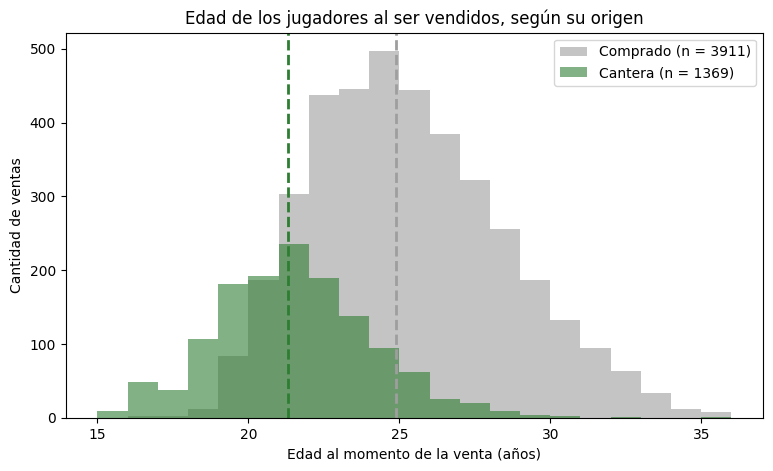

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.arange(15, 37, 1)
for grupo, color in [("comprado", "#9e9e9e"), ("cantera", "#2e7d32")]:
    edades = ventas.loc[ventas["grupo"] == grupo, "edad_venta"]
    ax.hist(edades, bins=bins, alpha=0.6, color=color, label=f"{grupo.capitalize()} (n = {len(edades)})")
    ax.axvline(edades.median(), color=color, linestyle="--", linewidth=2)
ax.set_title("Edad de los jugadores al ser vendidos, según su origen")
ax.set_xlabel("Edad al momento de la venta (años)")
ax.set_ylabel("Cantidad de ventas")
ax.legend()
plt.savefig("figuras/grafico1_edad_venta.png", dpi=300, bbox_inches="tight")
plt.show()

Los canteranos se venden mucho más jóvenes: la mitad se vende antes de los 21 años, mientras que los comprados se venden alrededor de los 25. Los clubes formadores venden a sus juveniles apenas muestran nivel en primera, y casi no hay canteranos vendidos después de los 27.

#### **Gráfico 2: origen de los ingresos por liga.** Barras apiladas con el porcentaje de los ingresos por ventas que viene de canteranos (verde) y de comprados (gris). Los rombos negros marcan el porcentaje contando solo los canteranos confirmados. Entre paréntesis, la cantidad de ventas de cada liga.

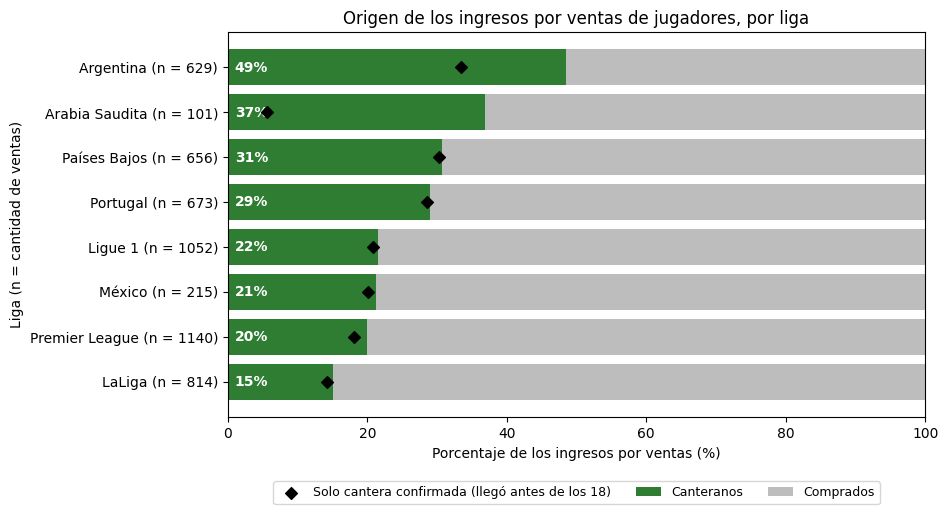

In [ ]:
nombres_ligas = {"GB1": "Premier League", "ES1": "LaLiga", "FR1": "Ligue 1", "PO1": "Portugal",
                 "NL1": "Países Bajos", "ARG1": "Argentina", "MEX1": "México", "SA1": "Arabia Saudita"}
datos = ingresos_liga.sort_values("cantera_%")
etiquetas = [f"{nombres_ligas[l]} (n = {n})" for l, n in zip(datos.index, datos["ventas"])]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(etiquetas, datos["cantera_%"], color="#2e7d32", label="Canteranos")
ax.barh(etiquetas, 100 - datos["cantera_%"], left=datos["cantera_%"], color="#bdbdbd", label="Comprados")
for i, valor in enumerate(datos["cantera_%"]):
    ax.text(1, i, f"{valor:.0f}%", va="center", ha="left", color="white", fontweight="bold")
ax.scatter(datos["confirmada_%"], etiquetas, marker="D", color="black", zorder=3,
           label="Solo cantera confirmada (llegó antes de los 18)")
ax.set_title("Origen de los ingresos por ventas de jugadores, por liga")
ax.set_xlabel("Porcentaje de los ingresos por ventas (%)")
ax.set_ylabel("Liga (n = cantidad de ventas)")
ax.set_xlim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9)
plt.savefig("figuras/grafico2_ingresos_por_liga.png", dpi=300, bbox_inches="tight")
plt.show()

Argentina es la liga que más depende de sus inferiores, seguida por las formadoras europeas (Países Bajos y Portugal). La Premier y LaLiga son las que menos dependen de ellas. El caso de Arabia muestra por qué hay que revisar la clasificación: la barra verde es alta, pero el rombo está casi en cero, porque sus canteranos son en realidad jugadores sin historial juvenil registrado.

#### **Gráfico 3: edad de compra y ganancia de la reventa.** Cada punto gris es la reventa de un jugador comprado, con la edad a la que llegó al club y la ganancia que dejó. La línea roja une las ganancias medianas de cada tramo de edad. El eje vertical usa una escala logarítmica que admite valores negativos (pérdidas), porque las ganancias van de unos pocos miles a más de €100 M.

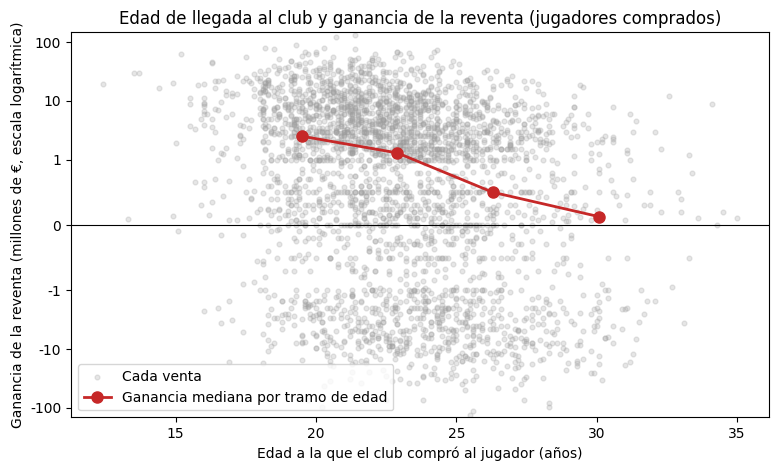

In [ ]:
comprados = ventas[(ventas["grupo"] == "comprado") & ventas["ganancia"].notna()]
medianas = comprados.groupby("tramo_edad_llegada", observed=True).agg(
    edad=("edad_llegada", "median"), ganancia=("ganancia", "median"))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(comprados["edad_llegada"], comprados["ganancia"], alpha=0.25, s=12, color="#9e9e9e", label="Cada venta")
ax.plot(medianas["edad"], medianas["ganancia"], color="#c62828", marker="o", markersize=8, linewidth=2,
        label="Ganancia mediana por tramo de edad")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_yscale("symlog", linthresh=1)
ax.set_yticks([-100, -10, -1, 0, 1, 10, 100])
ax.set_yticklabels(["-100", "-10", "-1", "0", "1", "10", "100"])
ax.set_title("Edad de llegada al club y ganancia de la reventa (jugadores comprados)")
ax.set_xlabel("Edad a la que el club compró al jugador (años)")
ax.set_ylabel("Ganancia de la reventa (millones de €, escala logarítmica)")
ax.legend()
plt.savefig("figuras/grafico3_edad_ganancia.png", dpi=300, bbox_inches="tight")
plt.show()

Hay mucha dispersión: en todas las edades hay reventas con grandes ganancias y con pérdidas. Pero la tendencia es clara: la ganancia mediana cae a medida que aumenta la edad de compra, de €2,5 M para los comprados antes de los 21 a casi cero para los comprados después de los 29. Un jugador joven tiene más margen para revalorizarse antes de la reventa.

#### **Exportación para el sitio web.** Guardamos la tabla de ventas con las columnas que usa el sitio, para publicar los resultados.

In [ ]:
columnas_sitio = ["jugador", "club_vendedor", "club_comprador", "liga", "temporada_venta", "grupo",
                  "fee_venta", "fee_compra", "anios_en_club", "edad_venta"]
ventas[columnas_sitio].to_csv("ventas.csv", index=False)
print("CSV exportado:", len(ventas), "filas")
print("Gráficos guardados:", os.listdir("figuras"))

CSV exportado: 5280 filas
Gráficos guardados: ['grafico2_ingresos_por_liga.png', 'grafico3_edad_ganancia.png', 'grafico1_edad_venta.png']
